### TASK 1: DATA CLEANING & PREPROCESSING

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Step 1: Import dataset using Pandas
project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
data_dir = project_root / 'data'
df = pd.read_csv(data_dir / 'netflix_titles.csv')
print("Initial Dataset Shape:", df.shape)

# Step 2: Identify missing and duplicate records
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\nDuplicate Rows Count:", df.duplicated().sum())

# Step 3: Handle null values and inconsistent formats
for col in ['director', 'country']:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

if 'cast' in df.columns:
    df['cast'] = df['cast'].fillna('Unknown')

if 'rating' in df.columns:
    mode_value = df['rating'].mode(dropna=True)
    df['rating'] = df['rating'].fillna(mode_value[0] if not mode_value.empty else 'Unknown')

if 'date_added' in df.columns:
    df['date_added'] = df['date_added'].fillna('Unknown')

# Strip leading/trailing whitespaces from string-like columns only if present
str_cols = ['title', 'type', 'director', 'cast', 'country', 'rating', 'listed_in']
for col in str_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Step 4: Transform categorical and date-related columns
df['date_added_clean'] = df['date_added'].str.strip()
df['date_added_clean'] = pd.to_datetime(df['date_added_clean'], errors='coerce')
df['year_added'] = df['date_added_clean'].dt.year
df['month_added'] = df['date_added_clean'].dt.month_name()

if 'duration' in df.columns:
    df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype(float)

# Step 5: Create a clean dataset for further analysis
df.to_csv(data_dir / 'cleaned_netflix_data.csv', index=False)
print(f"\nCleaned dataset successfully saved to '{data_dir / 'cleaned_netflix_data.csv'}'.")


Initial Dataset Shape: (8790, 10)

--- Missing Values ---
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Rows Count: 0

Cleaned dataset successfully saved to 'C:\Users\DELL\Desktop\Auspify Tech\netflix-project\data\cleaned_netflix_data.csv'.


### TASK 2: EXPLORATORY DATA ANALYSIS (EDA)


--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   show_id           8790 non-null   object        
 1   type              8790 non-null   object        
 2   title             8790 non-null   object        
 3   director          8790 non-null   object        
 4   country           8790 non-null   object        
 5   date_added        8790 non-null   object        
 6   release_year      8790 non-null   int64         
 7   rating            8790 non-null   object        
 8   duration          8790 non-null   object        
 9   listed_in         8790 non-null   object        
 10  date_added_clean  8790 non-null   datetime64[ns]
 11  year_added        8790 non-null   int32         
 12  month_added       8790 non-null   object        
 13  duration_num      8790 non-null   float64       

C:\Users\DELL\AppData\Local\Temp\ipykernel_17616\2856000208.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='type', palette='Set2')


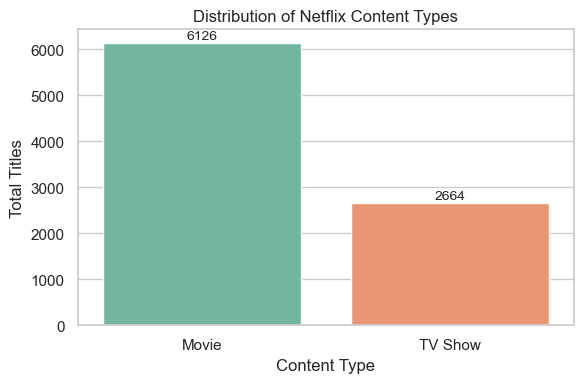

C:\Users\DELL\AppData\Local\Temp\ipykernel_17616\2856000208.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')


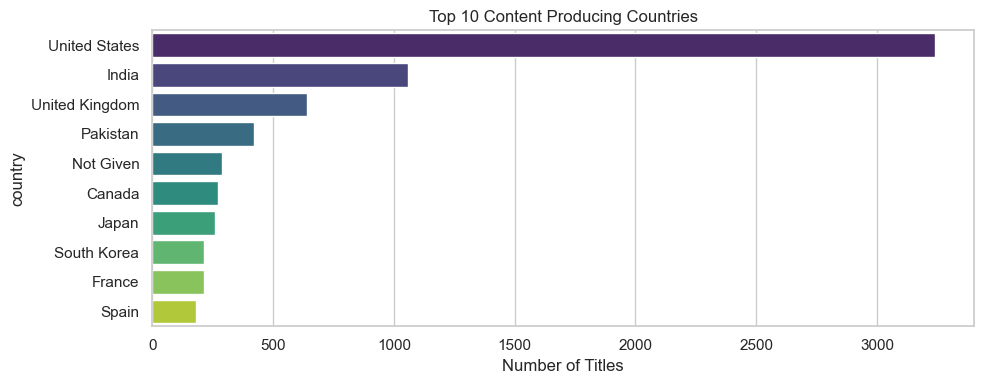

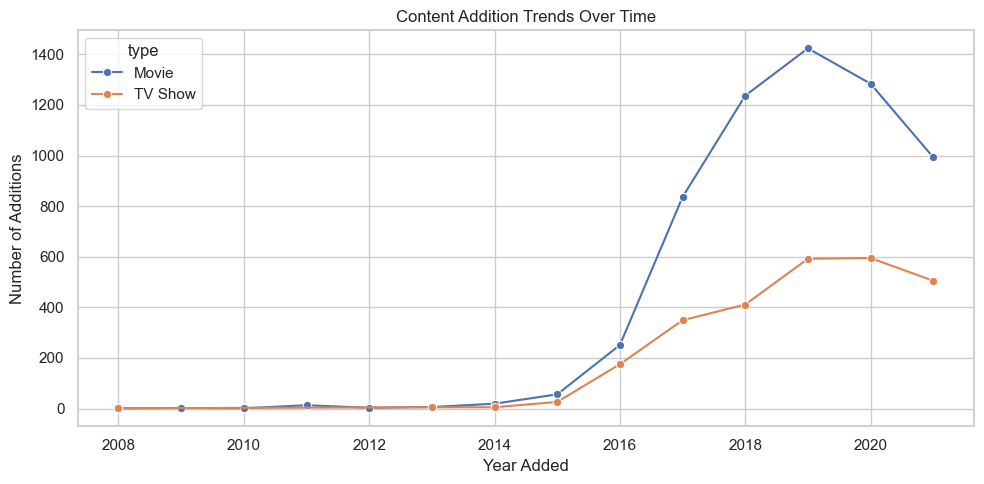


--- EDA Insights Summary ---
1. Movies constitute 6126 of total catalog titles.
2. Top country producing content on Netflix is United States with 3240 titles.


In [3]:
sns.set_theme(style="whitegrid")

# Step 1: Analyze dataset structure and statistics
print("\n--- Cleaned Dataset Info ---")
print(df.info())
print("\n--- Numerical Summary ---")
print(df.describe())

# Step 2: Study content distribution by type
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='type', palette='Set2')
plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Total Titles")
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

# Step 3: Identify top countries and categories
top_countries = (
    df[df['country'] != 'Unknown']['country']
    .dropna()
    .astype(str)
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 4))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.title("Top 10 Content Producing Countries")
plt.xlabel("Number of Titles")
plt.tight_layout()
plt.show()

# Step 4: Create visualizations for key metrics
yearly_additions = df.groupby(['year_added', 'type']).size().reset_index(name='count')
plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly_additions, x='year_added', y='count', hue='type', marker='o')
plt.title("Content Addition Trends Over Time")
plt.xlabel("Year Added")
plt.ylabel("Number of Additions")
plt.tight_layout()
plt.show()

# Step 5: Summarize findings
print("\n--- EDA Insights Summary ---")
print(f"1. Movies constitute {len(df[df['type'] == 'Movie'])} of total catalog titles.")
print(f"2. Top country producing content on Netflix is {top_countries.index[0]} with {top_countries.iloc[0]} titles.")